# Локальные признаки в регрессии

Рассмотрим ещё одну идею для формирования признаков для последующего применения линейной регрессии. Идея состоит в формировании из вектора $x$ некоторого вектора $z$, такого, чтобы при построении регрессионной модели $y=zw$ изменение одного веса $w_i$ приводило к изменению не всей зависимости данных, а лишь к локальному изменению зависимости. К примеру, чтобы изменение веса $w_1$ приводило к изменению функции в окрестности $0$, а веса $w_3$ в окрестности $6$.

Для применения полиномиальных признаков или каких-либо других <b>глобальных признаков</b> требуется иметь представление о виде зависимости в данных. Локальные признаки не требуют особых предположений о данных. 

То есть мы бы хотели получить что-то такое:

<img style="width: 50%; max-width: 960px; display: block; margin: 0 auto;" src="https://i.postimg.cc/YSR03KLP/rbf-example.png"/>

Поменялся один вес $w_1$ и функция поменяла свой вид лишь в окрестности точки 0.

Необходимо выбрать набор функций $(\varphi_1,\dots,\varphi_m)$, с помощью которых вектор $x$ преобразуется в вектор $z$, размерности $m$:

$$
\begin{pmatrix}
x_1
\\
\vdots
\\
x_n
\end{pmatrix}
\rightarrow
\begin{pmatrix}
\varphi_1(x_1,\dots,x_n)
\\
\vdots
\\
\varphi_m(x_1,\dots,x_n)
\end{pmatrix}$$

Единственное требование, что функции $\varphi$ должны иметь большое ненулевое значение в некоторой области и быстро приближаться к нулю вне этой области, это и есть **локальность**.

Рассмотрим применение радиальных базисных функций, а точнее гауссовских функций в качестве функций $\varphi$, который выглядят следующим образом:

$$\varphi(x; \mu)=e^{-\frac{1}{2s^2}||x-\mu||^2}$$

Для получения же базиса $\varphi_1,\dots,\varphi_m$ распределим центры $\mu_1,\dots,\mu_m$ равномерно на отрезке $[x_{min},x_{max}]$, на котором распределены данные. То есть $\mu_i=x_{min}+\frac{i-1}{m-1}(x_{max}-x_{min})$, далее базисные функции определяются как $\varphi_i(x)=\varphi(x;\mu_i)$.

Параметр $s$ имеет смысл выбирать пропорционально расстоянию между центрами соседних функций.

Для этого опишем класс-трансформер, который будет преобразовывать вектор $x$ в вектор $z$.

In [1]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge, RANSACRegressor, TheilSenRegressor
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import pandas as pd

In [2]:
# функция для генерации данных
def generate_samples(function, n_samples, x_min=0, x_max=10, sigma=1):
    x = np.random.uniform(x_min, x_max, n_samples)
    y = function(x) + np.random.normal(0, sigma, n_samples)
    return x, y

In [3]:
## Класс для преобразования данных в гауссовские признаки
class GaussianFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, N, width_factor=.5):
        self.N = N
        self.width_factor = width_factor
    
    @staticmethod
    def _gauss_basis(x, center, width, axis=None):
        arg = (x - center) / width
        return np.exp(-0.5 * np.sum(arg ** 2, axis))
        
    def fit(self, X, y=None):
        self.centers_ = np.linspace(X.min(), X.max(), self.N)
        self.width_ = self.width_factor * (self.centers_[1] - self.centers_[0])
        return self
        
    def transform(self, X):
        return self._gauss_basis(X[:, :, None], self.centers_, self.width_, axis=1)

Посмотрим эффект на малом числе точек. Мы видим довольно гладкое приближение 

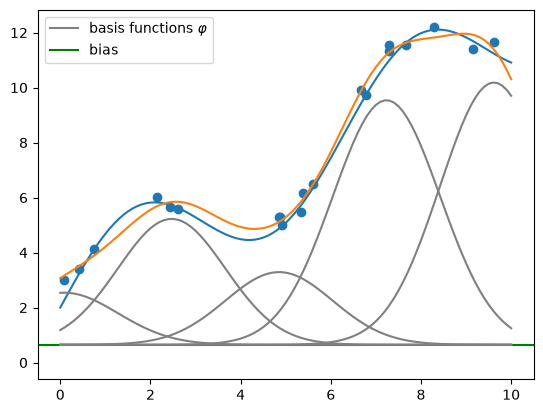

In [4]:
# Реальная зависимость в данных
relation = lambda x: 2 + x + 2 * np.sin(x) # использование numpy-функций позволяет использовать операции с массивами
# генерируем выборку
num_samples = 20    # Размер выборки
sigma = 0.3          # Дисперсия шума
x_min, x_max = 0, 10
x, center = generate_samples(relation, num_samples, x_min, x_max, sigma)

gf = GaussianFeatures(5)
lr = LinearRegression()
model = make_pipeline(gf, lr)

model.fit(x[:,None], center)

t = np.linspace(x_min, x_max, 101)

plt.scatter(x, center)
plt.plot(t, relation(t))

plt.plot(t, model.predict(t[:,None]))
plt.plot([0],[0], color="gray", label="basis functions $\\varphi$")
plt.axhline(lr.intercept_, color = "green", label="bias")
plt.plot(t, lr.intercept_ + gf.transform(t[:,None]) * lr.coef_, color="gray")
plt.legend()

Пример на большем участке данных:

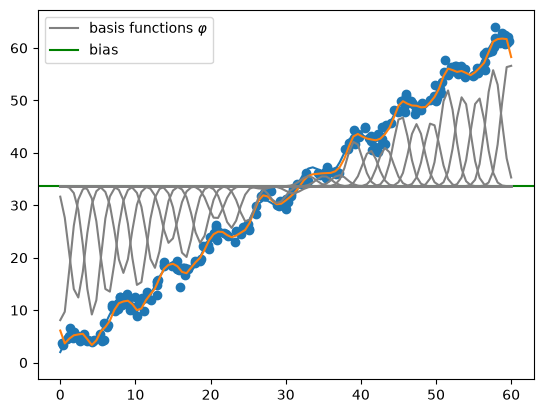

In [5]:
# Реальная зависимость в данных
relation = lambda x: 2 + x + 2 * np.sin(x) # использование numpy-функций позволяет использовать операции с массивами
# генерируем выборку
num_samples = 220    # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 60
x, center = generate_samples(relation, num_samples, x_min, x_max, sigma)

gf = GaussianFeatures(30)
lr = LinearRegression()
model = make_pipeline(gf, lr)

model.fit(x[:,None], center)

t = np.linspace(x_min, x_max, 101)

plt.scatter(x, center)
plt.plot(t, relation(t))

plt.plot(t, model.predict(t[:,None]))
plt.plot([0],[0], color="gray", label="basis functions $\\varphi$")
plt.axhline(lr.intercept_, color = "green", label="bias")
plt.plot(t, lr.intercept_ + gf.transform(t[:,None]) * lr.coef_, color="gray")
plt.legend()

А вот обучить полином на том же отрезке данных не удастся:

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.8032280392786252e-16.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


(3.5828016304367916, 43.35383604008811)

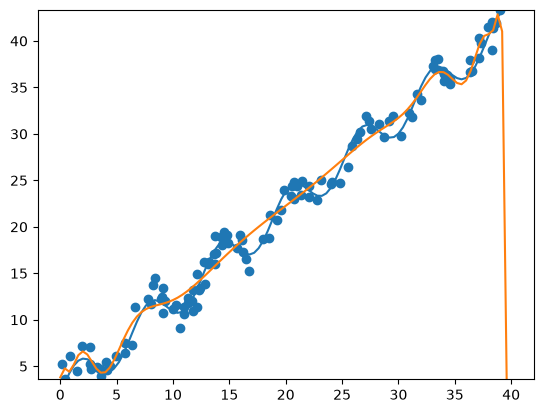

In [6]:
# Реальная зависимость в данных
relation = lambda x: 2 + x + 2 * np.sin(x) # использование numpy-функций позволяет использовать операции с массивами
# генерируем выборку
num_samples = 120    # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 40
x, center = generate_samples(relation, num_samples, x_min, x_max, sigma)

scaler = StandardScaler()
gf = PolynomialFeatures(degree=28)
lr = Ridge(alpha=0.1)
model = make_pipeline(scaler, gf, lr)

model.fit(x[:,None], center)

t = np.linspace(x_min, x_max, 101)

plt.scatter(x, center)
plt.plot(t, relation(t))

plt.plot(t, model.predict(t[:,None]))
plt.ylim(center.min(), center.max())

(1.6879574538058773, 24.5466362672866)

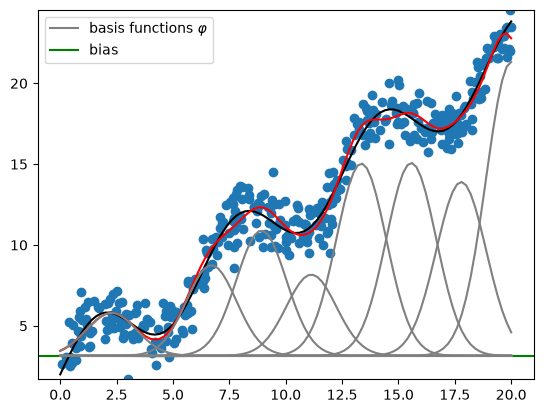

In [7]:
# Реальная зависимость в данных
relation = lambda x: 2 + x + 2 * np.sin(x) # использование numpy-функций позволяет использовать операции с массивами
# генерируем выборку
num_samples = 400    # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 20
x, center = generate_samples(relation, num_samples, x_min, x_max, sigma)

gf = GaussianFeatures(10,0.5)
lr = LinearRegression()
model = make_pipeline(gf, lr)

model.fit(x[:,None], center)

t = np.linspace(x_min, x_max, 101)

plt.scatter(x, center)
plt.plot(t, relation(t), color="black")

plt.plot(t, model.predict(t[:,None]),color="red")
plt.plot([0],[0], color="gray", label="basis functions $\\varphi$")
plt.axhline(lr.intercept_, color = "green", label="bias")
plt.plot(t, lr.intercept_ + gf.transform(t[:,None]) * lr.coef_, color="gray")
plt.legend()
plt.ylim(center.min(), center.max())

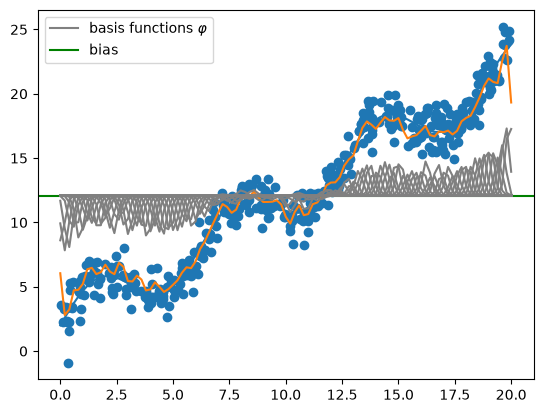

In [8]:
# Реальная зависимость в данных
relation = lambda x: 2 + x + 2 * np.sin(x) # использование numpy-функций позволяет использовать операции с массивами
# генерируем выборку
num_samples = 400    # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 20
x, center = generate_samples(relation, num_samples, x_min, x_max, sigma)

gf = GaussianFeatures(120,1)
lr = Ridge()
model = make_pipeline(gf, lr)

model.fit(x[:,None], center)

t = np.linspace(x_min, x_max, 101)

plt.scatter(x, center)
plt.plot(t, relation(t))

plt.plot(t, model.predict(t[:,None]))
plt.plot([0],[0], color="gray", label="basis functions $\\varphi$")
plt.axhline(lr.intercept_, color = "green", label="bias")
plt.plot(t, lr.intercept_ + gf.transform(t[:,None]) * lr.coef_, color="gray")
plt.legend()

# Робастная регрессия

Поговорим о методах робастной регрессии(от англ. robust - надёжный, устойчивый). Эти методы направлены на построение модели, устойчивой к выбросам в данных. 

Выбросы в данных (англ. outliers) — это аномальные наблюдения, которые существенно отклоняются от общего распределения или закономерностей в анализируемом наборе данных. Они могут быть вызваны сбоями в сборе и передаче данных или простыми человеческими ошибками. Иногда, конечно, выбросы могут оказаться просто аномальными данными, выбивающимися из общей совокупности данных.

Проблемой обычной линейной регрессии является слишком сильное влияние выбросов на итоговый результат. Вызвано это вероятностным предположением, которое делается при применении линейной регрессии. Это предположение о нормальном шуме, наложенном на данные. 

Говорят, что нормальное распределение имеет "лёгкие" хвосты распределения, это значит, что получить значения, которые сильно отклоняются от среднего почти невозможно. Наверняка вы слышали про правило "трёх сигм", которое гласит, что для величины, распределённой по нормальному закону $X\sim N(\mu,\sigma^2)$, выполнено: $$P(|X-\mu|<3\sigma) \approx 0.997,$$ то есть вероятность попасть в отрезок от минус трёх до плюс трёх сигм почти единица.

Поэтому значение, имеющее сильное отклонение, будет иметь очень сильное влияние на вид итоговой зависимости.

Посмотрим это на примере:

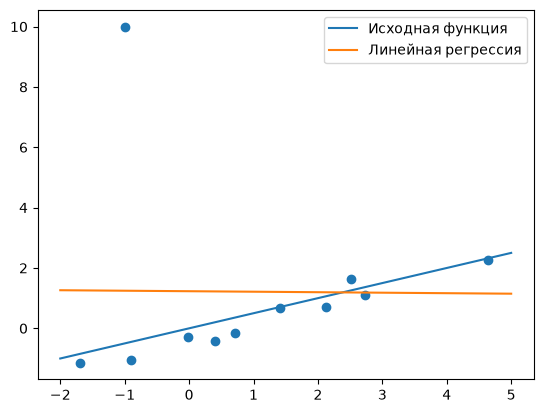

In [9]:
np.random.seed(51)

b = 0.5
# генерируем выборку
x_min, x_max = -2, 5
x = np.random.uniform(x_min, x_max, 10)
center = x * b + np.random.normal(0, 0.5, 10)
# добавляем аномальную точку
x = np.append(x, -1)
center = np.append(center, 10)

model = LinearRegression()
model.fit(x[:,None],center)
t = np.linspace(x_min, x_max, 200)
# рисование
plt.scatter(x, center)
plt.plot(t, b * t, label="Исходная функция")
plt.plot(t, model.predict(t[:,None]), label="Линейная регрессия")
plt.legend()

Как мы видим, всего одна точка очень сильно изменила получаемую функцию. Мы бы хотели научиться игнорировать такие аномальные точки.

## RANSAC регрессия

RANSAC Расшифровывается как RANdom SAmple Consensus, в переводе "случайный консенсус выборки". Идея метода состоит в том, что точки данных делятся на два вида: нормальные и выбросы. Задача сводится к тому, чтобы отличить одни от других. Реализуется это следующим алгоритмом:
1. Выбрать случайное подмножество входных данных;
2. Обучить на них модель;
3. Посмотреть, насколько хорошо модель подходит имеющимся данным; подмножество точек, которые подходят «хорошо» (что бы это ни значило), называется консенсусным множеством (consensus set) для текущей модели;
4. Если консенсусное множество S слишком маленькое (опять же что бы это ни значило), значит, нам не повезло с моделью и лучше вернуться к перво му шагу;
5. А если достаточно большое, то можно подсчитать, насколько хорошо модель подходит точкам из S, и если ошибка оказалась меньше, чем на предыдущих попытках, то сохранить модель как лучшую и тогда уже перезапускать процесс.

Изначально алгоритм кажется не очень сложным, но множество неточностей, требующих формализации, всё усложняет. К счастью, в sci-kit learn есть реализация этого метода. Тем не менее на нас всё ещё ложится ответственность за выбор параметров, отвечающих за размер подмножества, отвечающих за принятие или непринятие точек данных, отвечающих за размер консенсусного множества, отвечающих за количество итераций и т.д.

Мы же пока понадеемся на установленные параметры по умолчанию.

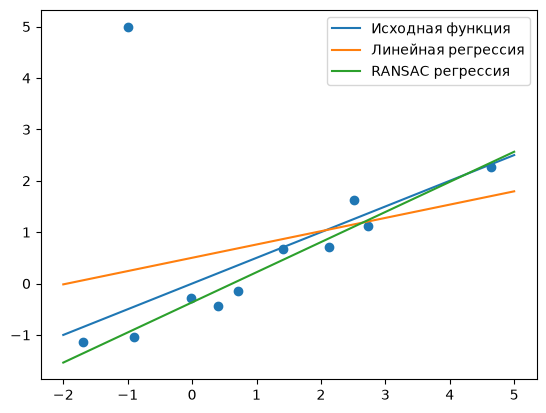

In [10]:
np.random.seed(51)

b = 0.5
# генерируем выборку
x_min, x_max = -2, 5
x = np.random.uniform(x_min, x_max, 10)
center = x * b + np.random.normal(0, 0.5, 10)
# добавляем аномальную точку
x = np.append(x, -1)
center = np.append(center, 5)

model = LinearRegression()
model.fit(x[:,None],center)
ransac = RANSACRegressor()
ransac.fit(x[:,None],center)
t = np.linspace(x_min, x_max, 200)
# рисование
plt.scatter(x, center)
plt.plot(t, b * t, label="Исходная функция")
plt.plot(t, model.predict(t[:,None]), label="Линейная регрессия")
plt.plot(t, ransac.predict(t[:,None]), label="RANSAC регрессия")
plt.legend()

Как мы видим, этот единичный выброс не влияет на RANSAC регрессию.

Но на самом деле, RANSAC регрессия устойчива и к большему количеству выбросов.

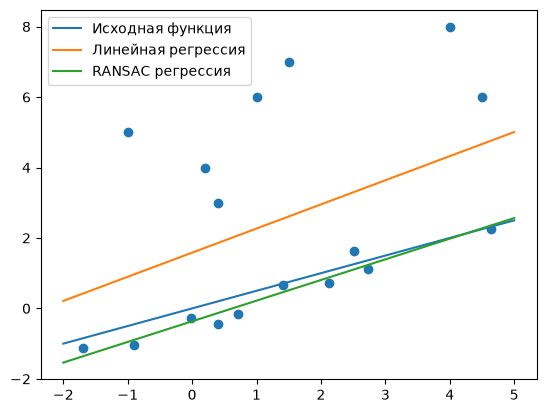

In [11]:
np.random.seed(51)

b = 0.5
# генерируем выборку
x_min, x_max = -2, 5
x = np.random.uniform(x_min, x_max, 10)
center = x * b + np.random.normal(0, 0.5, 10)
# добавляем аномальную точку
x = np.append(x, [-1, 0.2, 0.4, 1, 1.5, 4, 4.5])
center = np.append(center, [ 5,   4,   3, 6,   7, 8,   6])

model = LinearRegression()
model.fit(x[:,None], center)
ransac = RANSACRegressor()
ransac.fit(x[:,None], center)
t = np.linspace(x_min, x_max, 200)
# рисование
plt.scatter(x, center)
plt.plot(t, b * t, label="Исходная функция")
plt.plot(t, model.predict(t[:,None]), label="Линейная регрессия")
plt.plot(t, ransac.predict(t[:,None]), label="RANSAC регрессия")
plt.legend()

## Регрессия Тейла-сена

Этот метод регрессии основан на самой устойчивой оценке - на оценке параметров с использованием медианы.

Для этого через каждую пару точек проводятся прямые, коэффициент наклона прямой находится как медиана наклонов всех проведённых прямых. Свободный член также определяется как медиана остатков от вычитания $mx_i$:

$$m=Median_{i\neq j}\left(\frac{y_i-y_j}{x_i-x_j}\right), b=Median(y_i-mx_i).$$

Стоит отметить квадратичную $o(n^2)$ трудоёмкость данного алгоритма, требующую перебора всех пар точек.

Реализация этого метода также есть в sci-kit learn.

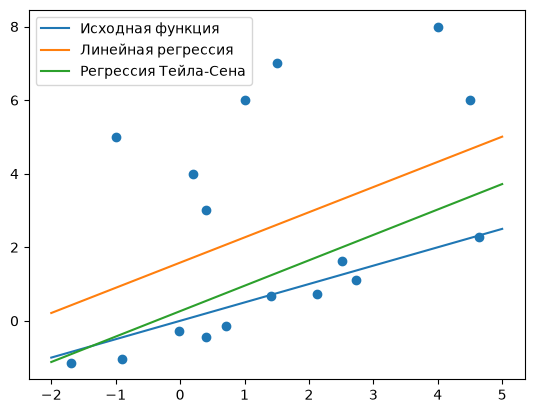

In [12]:
np.random.seed(51)

b = 0.5
# генерируем выборку
x_min, x_max = -2, 5
x = np.random.uniform(x_min, x_max, 10)
center = x * b + np.random.normal(0, 0.5, 10)
# добавляем аномальную точку
x = np.append(x, [-1, 0.2, 0.4, 1, 1.5, 4, 4.5])
center = np.append(center, [ 5,   4,   3, 6,   7, 8,   6])

model = LinearRegression()
model.fit(x[:,None], center)
theilsen = TheilSenRegressor()
theilsen.fit(x[:,None], center)
t = np.linspace(x_min, x_max, 200)
# рисование
plt.scatter(x, center)
plt.plot(t, b * t, label="Исходная функция")
plt.plot(t, model.predict(t[:,None]), label="Линейная регрессия")
plt.plot(t, theilsen.predict(t[:,None]), label="Регрессия Тейла-Сена")
plt.legend()

А теперь попробуем обе регрессии в многомерном случае (на примере локальных признаков).

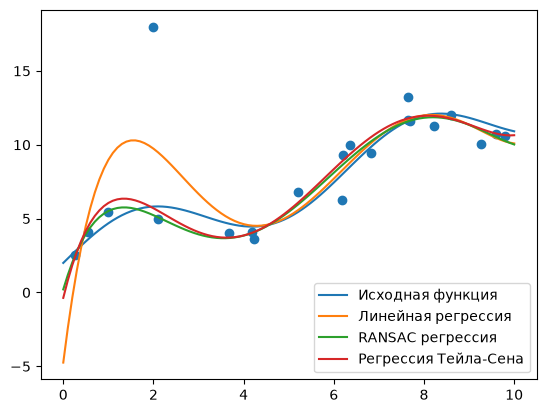

In [13]:
np.random.seed(52)
# Реальная зависимость в данных
relation = lambda x: 2 + x + 2 * np.sin(x) # использование numpy-функций позволяет использовать операции с массивами
# генерируем выборку
num_samples = 20    # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 10
x, center = generate_samples(relation, num_samples, x_min, x_max, sigma)
x = np.append(x, [2])
center = np.append(center, [18])

regression = make_pipeline(PolynomialFeatures(5), LinearRegression())
ransac = make_pipeline(PolynomialFeatures(5), RANSACRegressor())
theilsen = make_pipeline(PolynomialFeatures(5), TheilSenRegressor(random_state=0))  # было RANSACRegressor — опечатка

regression.fit(x[:,None], center)
ransac.fit(x[:,None], center)
theilsen.fit(x[:,None], center)

t = np.linspace(x_min, x_max, 101)

plt.scatter(x, center)
plt.plot(t, relation(t), label="Исходная функция")

plt.plot(t, regression.predict(t[:, None]), label="Линейная регрессия")
plt.plot(t, ransac.predict(t[:, None]), label="RANSAC регрессия")
plt.plot(t, theilsen.predict(t[:, None]), label="Регрессия Тейла-Сена")
plt.legend()

А теперь попробуем применить локальные признаки на том же самом примере.

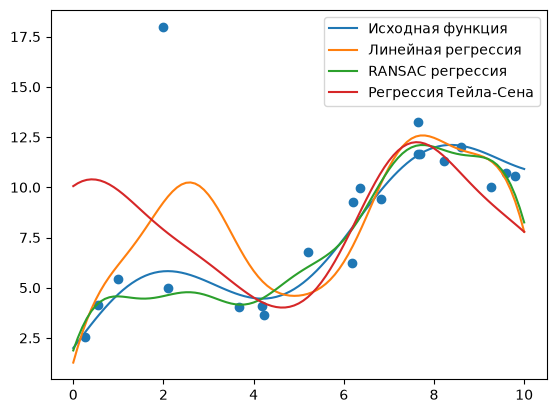

In [14]:
regression = make_pipeline(GaussianFeatures(5), LinearRegression())
ransac = make_pipeline(GaussianFeatures(5), RANSACRegressor())
theilsen = make_pipeline(GaussianFeatures(5), TheilSenRegressor(random_state=0))  # было RANSACRegressor — опечатка

regression.fit(x[:,None], center)
ransac.fit(x[:,None], center)
theilsen.fit(x[:,None], center)

t = np.linspace(x_min, x_max, 101)

plt.scatter(x, center)
plt.plot(t, relation(t), label="Исходная функция")

plt.plot(t, regression.predict(t[:, None]), label="Линейная регрессия")
plt.plot(t, ransac.predict(t[:, None]), label="RANSAC регрессия")
plt.plot(t, theilsen.predict(t[:, None]), label="Регрессия Тейла-Сена")
plt.legend()

# Коэффициент детерминации

На предыдущей паре мы разговаривали про оценку моделей регрессии. Был предложен вариант, основанный на вычислении функции ошибки на обучающей и тестовой выборках. На основании разницы ошибок мы делали вывод о силе переобучения модели. 

Но такой подход имеет явный недостаток: Размер ошибки напрямую зависит от масштаба целевой переменной, поэтому величина функции ошибки совсем ничего не говорит о самом обучения. 

Предположим, мы обучили модель, протестировали её и получили значение MSE=100. Плохо это или хорошо? Если мы предсказываем цену автомобиля, то это хорошо, а если температуру воздуха на улице, то уже не очень хорошо.

А хотелось бы иметь простую метрику с фиксированной шкалой, которая не меняла бы своего смысла от задачи к задаче.

Для этого вводится **коэффициент детерминации**:

$$R^2=1-\frac{SS_{res}}{SS_{tot}}$$

где:
- $SS_{res}=\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2$ $-$ сумма квадратов остатков регрессии, соответствует ошибке, которую делает модель, то есть это дисперсия ответов модели. 
- $SS_{tot}=\frac{1}{n}\sum_{i=1}^{n}(y-\overline{y})^2$ $-$ общая сумма квадратов, это дисперсия целевой переменной.

$\hat{y}_i$ $-$ предсказание модели, $y_i$ $-$ настоящее значение, $\overline{y}=\frac{1}{n}\sum_{i=1}^ny_i$ $-$ среднее значение.

Коэффициент детерминации отражает то, какую часть дисперсии данных модель смогла объяснить. Чем значение ближе к единице, тем лучше. Принимать он может значения от $-\infty$ до $1$. Отрицательные значения можно получить на тестовой выборке, если модель сильно переобучена, обычно же если модель делает хоть сколько-то релевантный ответ, то коэффициент детерминации будет положителен.


<!-- При применении модели линейной регрессии выполняется равенство $SS_{reg}+SS_{res}=SS_{tot}$, $SS_{reg}=\sum_{i=1}^{n}(\hat{y}_i-\overline{y})^2$ $-$ дисперсия ответов модели. Поэтому формула может быть упрощена: -->

<!-- $$R^2=\frac{SS_{reg}}{SS_{tot}}.$$ -->



В scikit-learn есть возможность вычислить коэффициент детерминации вызвав метод `score` у модели.

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.5418103362278564e-20.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.052e+01, tolerance: 1.870e-02
  model = cd_fast.enet_coordinate_descent(


,name,train r2,test r2
0,OLS,0.930019,-0.428318
1,Ridge,0.926565,0.869849
2,Lasso,0.891820,0.869441


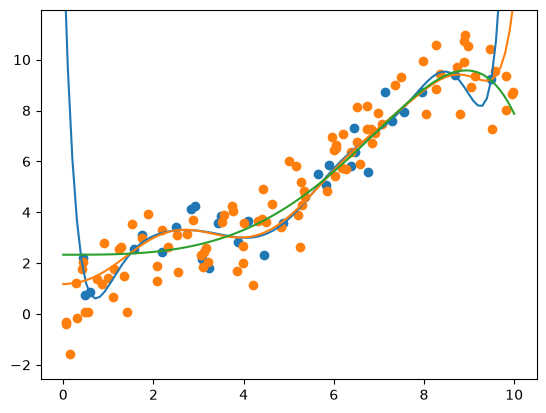

In [15]:
fun = lambda x: x + np.sin(x)
np.random.seed(51)
x_train, y_train = generate_samples(fun, 30, 0, 10, 1)
x_test, y_test = generate_samples(fun, 100, 0, 10, 1)
plt.scatter(x_train, y_train)
plt.scatter(x_test, y_test)

t = np.linspace(0,10,100)

models = [("OLS", LinearRegression()),
          ("Ridge", Ridge(alpha=1)),
          ("Lasso", Lasso(alpha=1)),
            ]
rez = []
for name,model in models:
    pipe = make_pipeline(PolynomialFeatures(degree=10), model)
    pipe.fit(x_train.reshape(-1, 1), y_train)
    
    rez.append({"name": name, 
                "train r2": pipe.score(x_train.reshape(-1,1), y_train),
                "test r2": pipe.score(x_test.reshape(-1,1), y_test),
                })
    plt.plot(t,pipe.predict(t.reshape(-1,1)))    
plt.ylim(y_test.min()-1, y_test.max()+1)

pd.DataFrame(rez)

Для регрессии без регуляризации коэффициент детерминации получился отрицательным из-за слишком большой ошибки на концах по причине резкого возрастания функции.

Если дисперсия шума, наложенного на данные, слишком большая, то мы получим низкий коэффициент детерминации потому что модель не способна описать этот шум.

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.5418103362278564e-20.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.174e+02, tolerance: 3.535e-02
  model = cd_fast.enet_coordinate_descent(


,name,train r2,test r2
0,OLS,0.407525,-7.887869
1,Ridge,0.366954,0.390091
2,Lasso,0.335885,0.383925


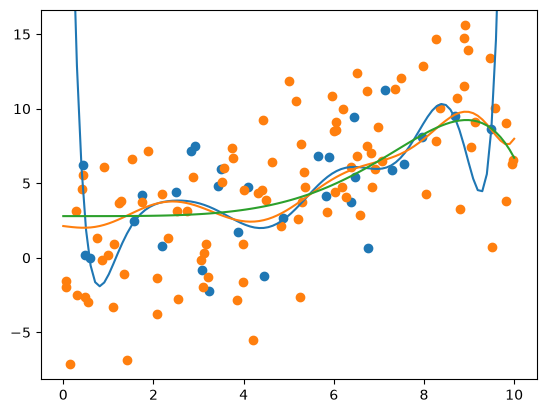

In [16]:
fun = lambda x: x + np.sin(x)
np.random.seed(51)
x_train, y_train = generate_samples(fun, 30, 0, 10, 4)
x_test, y_test = generate_samples(fun, 100, 0, 10, 4)
plt.scatter(x_train, y_train)
plt.scatter(x_test, y_test)

t = np.linspace(0,10,100)

models = [("OLS", LinearRegression()),
          ("Ridge", Ridge(alpha=1)),
          ("Lasso", Lasso(alpha=1)),
            ]
rez = []
for name,model in models:
    pipe = make_pipeline(PolynomialFeatures(degree=10), model)
    pipe.fit(x_train.reshape(-1, 1), y_train)
    
    rez.append({"name": name, 
                "train r2": pipe.score(x_train.reshape(-1,1), y_train),
                "test r2": pipe.score(x_test.reshape(-1,1), y_test),
                })
    plt.plot(t,pipe.predict(t.reshape(-1,1)))    
plt.ylim(y_test.min()-1, y_test.max()+1)

pd.DataFrame(rez)

# Домашнее задание

- Сгенерируйте выборку со сложной зависимостью. Обучите регрессию с локальными базисными признаками. Поэкспериментируйте с параметром ширины гауссиан. Какое значение оптимально? Объясните своё решение.
- Сгенерируйте выборку с простой линейной зависимостью. Добавьте в выборку выбросы (к примеру, для случайных точек замените $y$ на аномально большое значение). Обучите обычную и робастную линейную регрессию, выведите коэффициент детерминации и суммарную функции ошибки. Объясните полученные результаты.
- Для построенных моделей постройте распределение значений функции ошибки. Чем отличаются графики?

---
# Решение домашнего задания

In [17]:
import json, warnings
from sklearn.linear_model import HuberRegressor
from sklearn.metrics import mean_squared_error, r2_score
warnings.filterwarnings("ignore")
RESULTS = {}

## Задание 1. Ширина гауссовых базисных функций

Беру зависимость, в которой есть и медленная, и быстрая составляющая:

$$f(x) = 3\sin x + \sin 3x + 0.3x,\quad x\in[0,10],\quad \varepsilon\sim N(0, 0.5^2).$$

Обучающая выборка — 50 точек, валидационная (для выбора ширины) — 200, тестовая (для финальной оценки) — 2000. Число гауссиан фиксирую $N=20$, ширину задаю через `width_factor` — во сколько раз ширина гауссианы больше расстояния между соседними центрами.

In [18]:
f1 = lambda x: 3 * np.sin(x) + np.sin(3 * x) + 0.3 * x
SIGMA1 = 0.5

def gen1(n, rng):
    x = rng.uniform(0, 10, n)
    return x, f1(x) + rng.normal(0, SIGMA1, n)

rng = np.random.default_rng(1)
x1_tr, y1_tr = gen1(50, rng)
x1_va, y1_va = gen1(200, rng)
x1_te, y1_te = gen1(2000, rng)

widths = np.logspace(-1, 1.3, 30)
N1 = 20
rows = []
for wf in widths:
    model = make_pipeline(GaussianFeatures(N1, wf), LinearRegression()).fit(x1_tr[:, None], y1_tr)
    Phi = model[0].transform(x1_tr[:, None])
    rows.append({"width_factor": wf,
                 "train": mean_squared_error(y1_tr, model.predict(x1_tr[:, None])),
                 "val": mean_squared_error(y1_va, model.predict(x1_va[:, None])),
                 "test": mean_squared_error(y1_te, model.predict(x1_te[:, None])),
                 "cond": np.linalg.cond(Phi),
                 "w_norm": np.linalg.norm(model[-1].coef_)})
wdf = pd.DataFrame(rows)
best_wf = wdf.loc[wdf["val"].idxmin(), "width_factor"]
print(f"Лучший width_factor по валидации: {best_wf:.2f}")
print(wdf.iloc[::3].round(3).to_string(index=False))

Лучший width_factor по валидации: 1.07
 width_factor  train          val         test         cond       w_norm
        0.100  2.275 2.350007e+23 5.625168e+23 7.136666e+12 7.706264e+12
        0.173  1.420 9.395240e+06 1.218506e+07 2.812506e+04 2.676097e+04
        0.299  0.289 2.498400e+01 2.781400e+01 6.033300e+01 3.935800e+01
        0.517  0.095 5.390000e-01 7.600000e-01 1.182200e+01 4.498600e+01
        0.895  0.095 3.580000e-01 4.730000e-01 6.395400e+01 2.927400e+01
        1.548  0.092 4.170000e-01 5.660000e-01 3.983967e+04 3.089499e+03
        2.677  0.095 8.910000e-01 1.682000e+00 2.904696e+10 4.902626e+08
        4.629  0.100 6.930000e-01 7.920000e-01 3.926562e+16 1.232772e+11
        8.007  0.210 6.560000e-01 9.850000e-01 1.193263e+17 5.103460e+11
       13.848  0.361 8.300000e-01 9.680000e-01 2.095375e+17 2.237887e+12


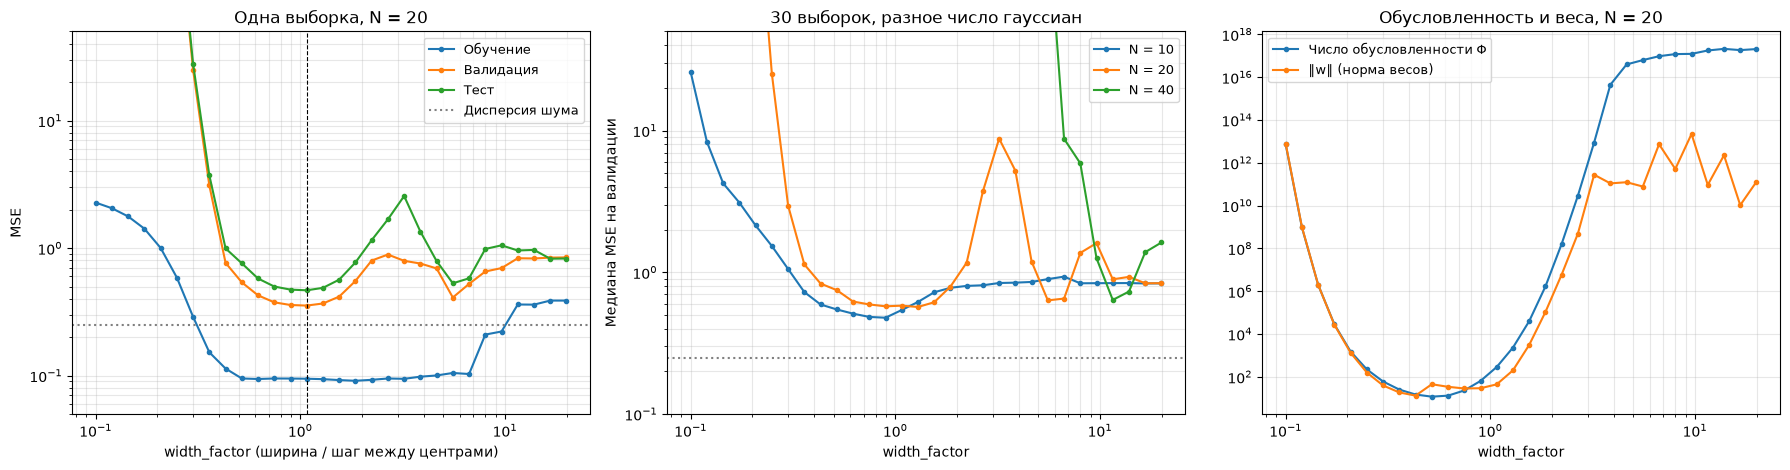

{10: 0.8947962141223854, 20: 1.2892728213968123, 40: 11.536364395567547}


In [19]:
# Повторяю эксперимент на 30 случайных выборках, чтобы оценка не зависела от одной реализации шума,
# и для разного числа гауссиан N
curves = {}
for N in (10, 20, 40):
    errs = []
    for seed in range(30):
        r = np.random.default_rng(100 + seed)
        xt, yt = gen1(50, r); xv, yv = gen1(300, r)
        errs.append([mean_squared_error(yv, make_pipeline(GaussianFeatures(N, wf), LinearRegression())
                                        .fit(xt[:, None], yt).predict(xv[:, None])) for wf in widths])
    curves[N] = np.median(errs, axis=0)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].plot(wdf.width_factor, wdf.train, "o-", ms=3, label="Обучение")
ax[0].plot(wdf.width_factor, wdf.val, "o-", ms=3, label="Валидация")
ax[0].plot(wdf.width_factor, wdf.test, "o-", ms=3, label="Тест")
ax[0].axhline(SIGMA1 ** 2, color="gray", ls=":", label="Дисперсия шума")
ax[0].axvline(best_wf, color="k", ls="--", lw=0.8)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_ylim(0.05, 50)
ax[0].set_xlabel("width_factor (ширина / шаг между центрами)"); ax[0].set_ylabel("MSE")
ax[0].set_title(f"Одна выборка, N = {N1}"); ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3, which="both")

for N, c in curves.items():
    ax[1].plot(widths, c, "o-", ms=3, label=f"N = {N}")
ax[1].axhline(SIGMA1 ** 2, color="gray", ls=":")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_ylim(0.1, 50)
ax[1].set_xlabel("width_factor"); ax[1].set_ylabel("Медиана MSE на валидации")
ax[1].set_title("30 выборок, разное число гауссиан"); ax[1].legend(fontsize=9); ax[1].grid(alpha=0.3, which="both")

ax[2].plot(wdf.width_factor, wdf["cond"], "o-", ms=3, label="Число обусловленности Φ")
ax[2].plot(wdf.width_factor, wdf["w_norm"], "o-", ms=3, label="‖w‖ (норма весов)")
ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xlabel("width_factor")
ax[2].set_title(f"Обусловленность и веса, N = {N1}"); ax[2].legend(fontsize=9); ax[2].grid(alpha=0.3, which="both")
fig.tight_layout(); fig.savefig("figures/width_curves.png", dpi=150, bbox_inches="tight"); plt.show()

RESULTS["task1"] = {
    "best_wf": float(best_wf),
    "best_val": float(wdf["val"].min()),
    "best_test": float(wdf.loc[wdf["val"].idxmin(), "test"]),
    "median_best_wf": {int(N): float(widths[np.argmin(c)]) for N, c in curves.items()},
    "median_best_mse": {int(N): float(c.min()) for N, c in curves.items()},
    "table": wdf.iloc[::3].round(4).to_dict(orient="records"),
}
print(RESULTS["task1"]["median_best_wf"])

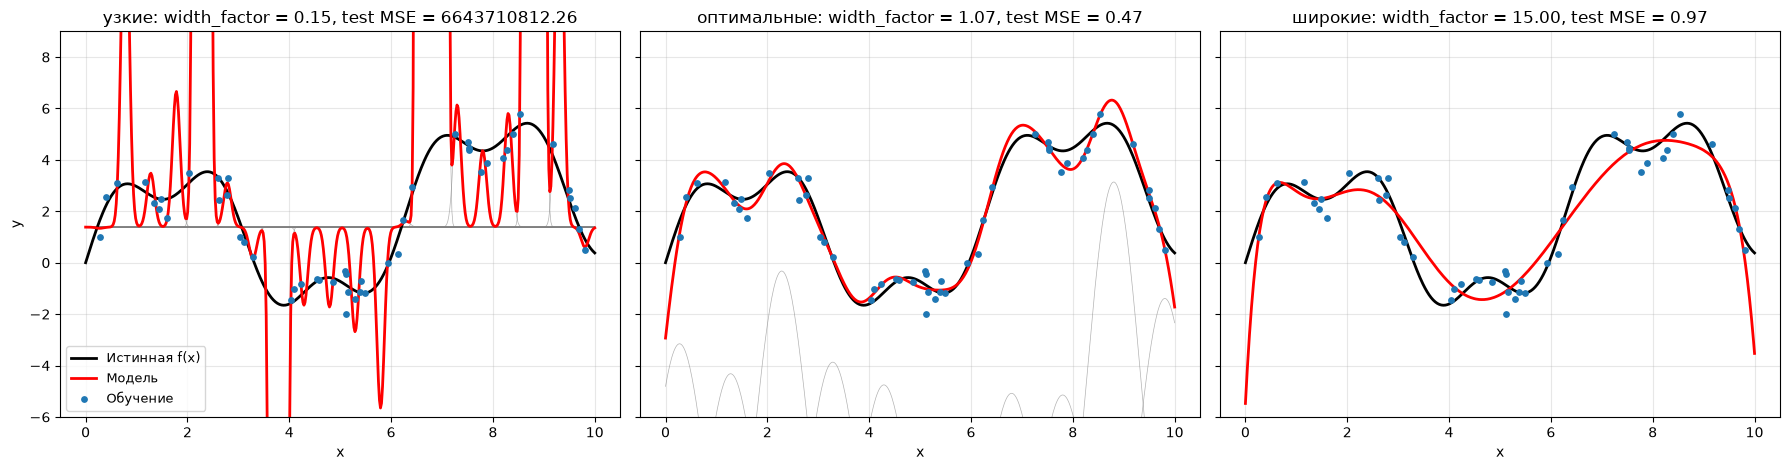

In [20]:
t = np.linspace(0, 10, 500)
show = [(0.15, "узкие"), (best_wf, "оптимальные"), (15.0, "широкие")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, (wf, name) in zip(axes, show):
    model = make_pipeline(GaussianFeatures(N1, wf), LinearRegression()).fit(x1_tr[:, None], y1_tr)
    gf, lr = model[0], model[-1]
    basis = gf.transform(t[:, None]) * lr.coef_
    ax.plot(t, lr.intercept_ + basis, color="gray", lw=0.5, alpha=0.6)
    ax.plot(t, f1(t), "k", lw=2, label="Истинная f(x)")
    ax.plot(t, model.predict(t[:, None]), "r", lw=2, label="Модель")
    ax.scatter(x1_tr, y1_tr, s=15, zorder=5, label="Обучение")
    test_mse = mean_squared_error(y1_te, model.predict(x1_te[:, None]))
    ax.set_title(f"{name}: width_factor = {wf:.2f}, test MSE = {test_mse:.2f}")
    ax.set_ylim(-6, 9); ax.set_xlabel("x"); ax.grid(alpha=0.3)
axes[0].set_ylabel("y"); axes[0].legend(fontsize=9)
fig.tight_layout(); fig.savefig("figures/width_examples.png", dpi=150, bbox_inches="tight"); plt.show()

**Какое значение оптимально и почему.**

- **Слишком узкие гауссианы** (`width_factor` ≲ 0.3): каждая базисная функция «видит» только крошечную окрестность своего центра. Между центрами все признаки почти нулевые, и модель проваливается к свободному члену («гребёнка» на левом графике). Хуже того, если рядом с каким-то центром нет обучающих точек, соответствующий столбец матрицы признаков почти нулевой, матрица плохо обусловлена (число обусловленности до $10^{12}$), веса получаются гигантскими, и модель даёт огромные выбросы между точками. Ошибка на тесте катастрофическая.
- **Слишком широкие** (`width_factor` ≳ 3): соседние гауссианы почти совпадают, признаки становятся почти линейно зависимыми, число обусловленности снова растёт до $10^{16}$, веса огромные и разных знаков. Модель теряет «локальность»: она сглаживает быстрые колебания (недообучение — правый график) и ведёт себя как полином высокой степени, «заворачиваясь» на краях отрезка. Ошибка ведёт себя немонотонно и неустойчиво от выборки к выборке.
- **Оптимум** — когда соседние гауссианы заметно перекрываются, но не совпадают: ширина порядка одного шага между центрами. По валидации лучшее значение `width_factor ≈ 1.07`, на тесте MSE ≈ 0.47 при дисперсии шума 0.25 — для 50 точек и 21 параметра это хороший результат. Ровно в этой области число обусловленности матрицы признаков минимально (правый график) — задача устойчива.

Что видно на среднем графике (медиана по 30 выборкам): для $N=10$ и $N=20$ оптимум находится около 0.9–1.3 шага между центрами, т.е. разумно задавать ширину *относительно шага сетки*. Но для $N=40$ (40 параметров на 50 точек) модель переобучается при любой «нормальной» ширине, и минимум сдвигается к очень широким гауссианам — там эффективное число степеней свободы меньше. Значит, ширина и число центров связаны между собой, и при большом числе центров нужна регуляризация (Ridge), а не только подбор ширины. Итоговое правило: число центров выбирать заметно меньше числа точек, ширину — порядка шага между центрами, и уточнять множитель по валидации или кросс-валидации.

## Задание 2. Линейная зависимость с выбросами

Генерирую $y=2x+1+\varepsilon$, $\varepsilon\sim N(0,1)$, 100 точек на $[0,10]$. Для 15% случайных точек заменяю $y$ на аномально большое значение (добавляю от 20 до 40). Для честной оценки дополнительно генерирую чистую тестовую выборку без выбросов.

Сравниваю: обычную регрессию (МНК), RANSAC, Тейла-Сена и Хьюбера (`HuberRegressor` — квадратичная потеря для малых остатков и линейная для больших).

In [21]:
rng2 = np.random.default_rng(7)
a_true, b_true = 1.0, 2.0
n2 = 100
x2 = rng2.uniform(0, 10, n2)
y2_clean = a_true + b_true * x2 + rng2.normal(0, 1, n2)
outlier_mask = np.zeros(n2, bool)
outlier_mask[rng2.choice(n2, size=15, replace=False)] = True
y2 = y2_clean.copy()
y2[outlier_mask] += rng2.uniform(20, 40, outlier_mask.sum())
x2_te = rng2.uniform(0, 10, 1000)
y2_te = a_true + b_true * x2_te + rng2.normal(0, 1, 1000)

models2 = {
    "МНК (LinearRegression)": LinearRegression(),
    "RANSAC": RANSACRegressor(random_state=0),
    "Тейл-Сен": TheilSenRegressor(random_state=0),
    "Хьюбер": HuberRegressor(),
}
rows2, resid = [], {}
for name, m in models2.items():
    m.fit(x2[:, None], y2)
    est = m.estimator_ if name == "RANSAC" else m
    pred = m.predict(x2[:, None])
    resid[name] = y2 - pred
    rows2.append({
        "модель": name,
        "наклон": float(np.ravel(est.coef_)[0]), "свободный член": float(est.intercept_),
        "R² (обучение, с выбросами)": r2_score(y2, pred),
        "Сумма квадратов ошибок (обучение)": float(np.sum((y2 - pred) ** 2)),
        "Сумма квадратов ошибок без выбросов": float(np.sum((y2 - pred)[~outlier_mask] ** 2)),
        "R² (чистый тест)": r2_score(y2_te, m.predict(x2_te[:, None])),
        "MSE (чистый тест)": mean_squared_error(y2_te, m.predict(x2_te[:, None])),
    })
res2 = pd.DataFrame(rows2).set_index("модель")
print(f"Истинная зависимость: y = {b_true}x + {a_true}; выбросов {outlier_mask.sum()} из {n2}")
res2.round(3)

Истинная зависимость: y = 2.0x + 1.0; выбросов 15 из 100


,наклон,свободный член,"R² (обучение, с выбросами)",Сумма квадратов ошибок (обучение),Сумма квадратов ошибок без выбросов,R² (чистый тест),MSE (чистый тест)
модель,,,,,,,
МНК (LinearRegression),2.803,1.720,0.345,12480.941,2312.374,0.200,28.218
RANSAC,1.977,0.998,0.198,15276.367,68.332,0.969,1.080
Тейл-Сен,2.044,0.902,0.214,14976.449,75.472,0.970,1.071
Хьюбер,2.015,1.079,0.213,14982.324,74.976,0.970,1.072


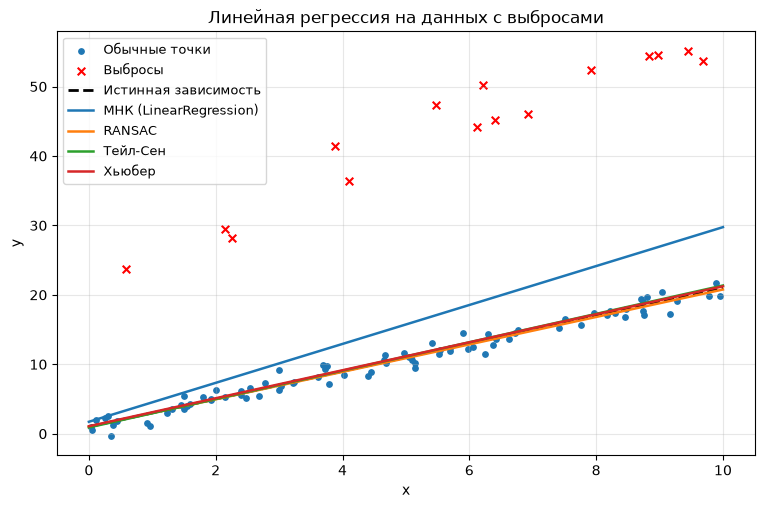

In [22]:
t = np.linspace(0, 10, 2)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(x2[~outlier_mask], y2[~outlier_mask], s=15, label="Обычные точки")
ax.scatter(x2[outlier_mask], y2[outlier_mask], s=30, color="red", marker="x", label="Выбросы")
ax.plot(t, a_true + b_true * t, "k--", lw=2, label="Истинная зависимость")
for name, m in models2.items():
    ax.plot(t, m.predict(t[:, None]), lw=1.8, label=name)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.set_title("Линейная регрессия на данных с выбросами")
fig.savefig("figures/robust_fit.png", dpi=150, bbox_inches="tight"); plt.show()
RESULTS["task2"] = res2.round(4).reset_index().to_dict(orient="records")
RESULTS["n_outliers"] = int(outlier_mask.sum())

**Объяснение результатов.**

- Обычная регрессия «тянется» к выбросам: прямая сдвигается вверх (свободный член сильно завышен), т.к. квадратичная функция ошибки делает каждый большой остаток очень «дорогим», и выгоднее немного ошибиться на всех точках, чем сильно на 15 выбросах.
- При этом на обучающей выборке **с выбросами** у МНК самая маленькая суммарная квадратичная ошибка и самый большой $R^2$ — и это не случайность, а определение МНК: среди всех прямых он минимизирует именно эту сумму. Робастные модели «жертвуют» выбросами, поэтому у них суммарная ошибка на обучении выше, а $R^2$ ниже. То есть по метрикам на загрязнённых данных МНК выглядит лучше всех, хотя на самом деле восстанавливает зависимость хуже всех.
- Если же посчитать ошибку на точках **без выбросов** или на чистой тестовой выборке, картина обратная: RANSAC, Тейл-Сен и Хьюбер почти точно восстанавливают $y=2x+1$, их $R^2$ на тесте близок к максимально возможному, а у МНК он заметно хуже.

Вывод: при наличии выбросов $R^2$ и MSE на обучающих данных вводят в заблуждение, модели нужно сравнивать на чистых данных или робастными метриками (например, медианной абсолютной ошибкой).

## Задание 3. Распределение значений функции ошибки

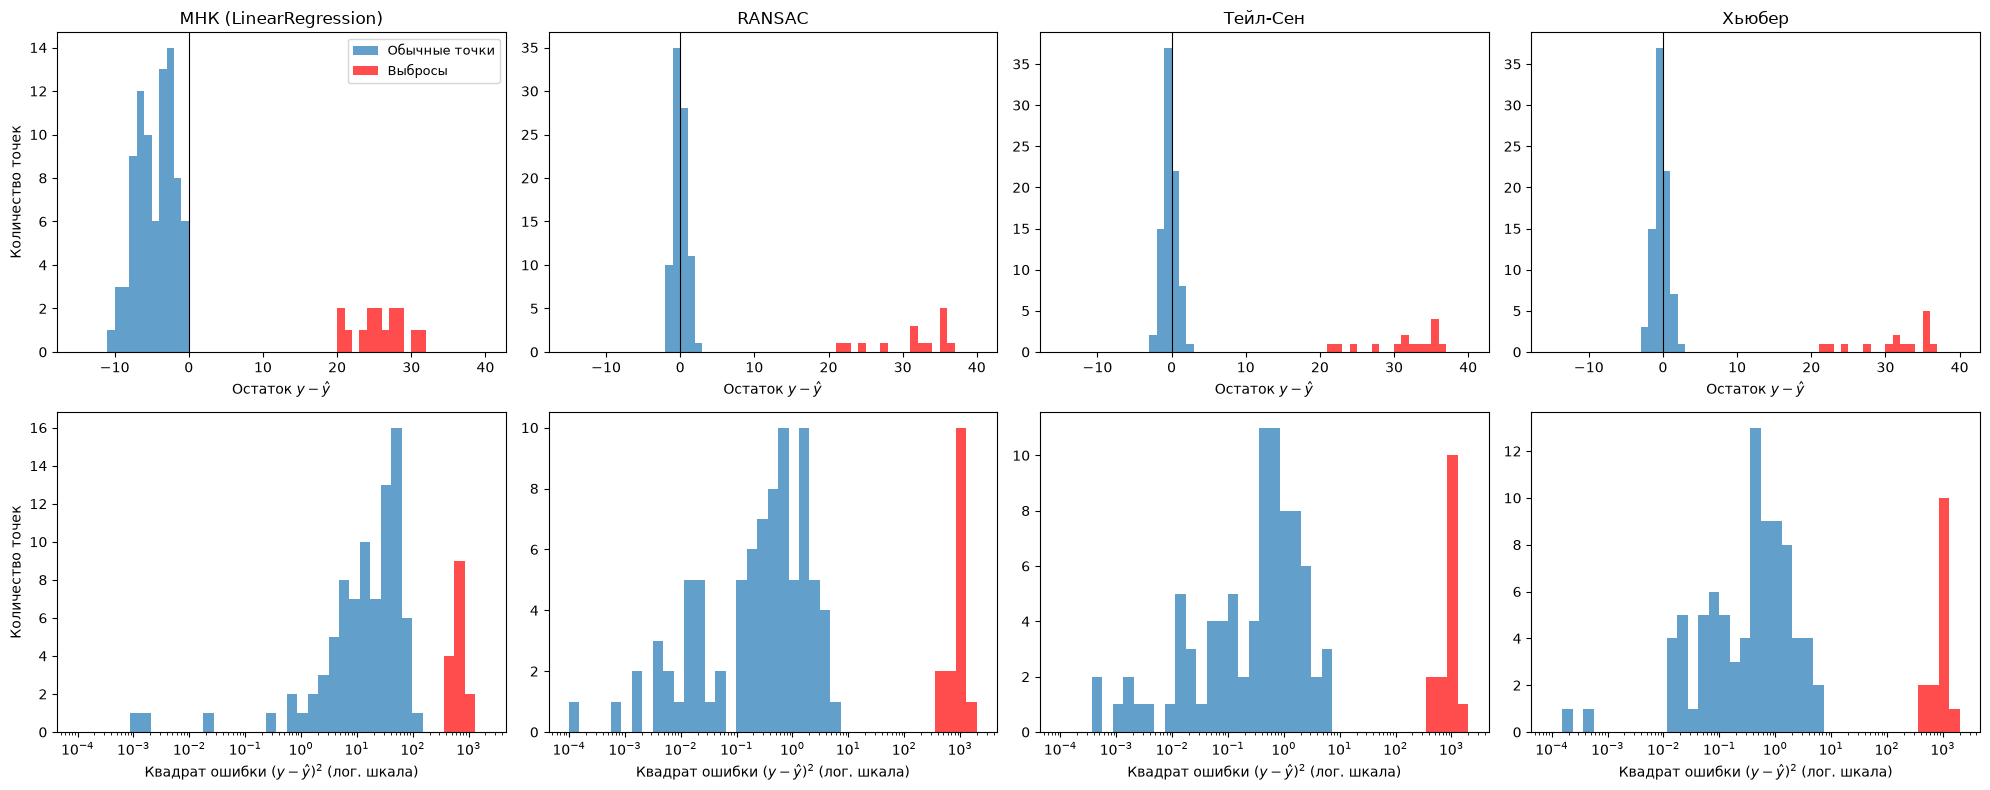

,медиана остатка (обычные),медиана |остатка| (обычные),медиана остатка (выбросы),доля SSE от выбросов
модель,,,,
МНК (LinearRegression),-4.584,4.584,25.536,0.815
RANSAC,-0.063,0.621,32.754,0.996
Тейл-Сен,-0.186,0.671,32.590,0.995
Хьюбер,-0.259,0.696,32.526,0.995


In [23]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex="row")
bins_signed = np.linspace(-15, 40, 56)
bins_sq = np.logspace(-4, 3.3, 40)
for j, (name, r) in enumerate(resid.items()):
    ax = axes[0, j]
    ax.hist(r[~outlier_mask], bins=bins_signed, alpha=0.7, label="Обычные точки")
    ax.hist(r[outlier_mask], bins=bins_signed, alpha=0.7, color="red", label="Выбросы")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(name); ax.set_xlabel("Остаток $y - \\hat y$")
    ax = axes[1, j]
    ax.hist(r[~outlier_mask] ** 2, bins=bins_sq, alpha=0.7)
    ax.hist(r[outlier_mask] ** 2, bins=bins_sq, alpha=0.7, color="red")
    ax.set_xscale("log"); ax.set_xlabel("Квадрат ошибки $(y - \\hat y)^2$ (лог. шкала)")
axes[0, 0].set_ylabel("Количество точек"); axes[1, 0].set_ylabel("Количество точек"); axes[0, 0].legend(fontsize=9)
fig.tight_layout(); fig.savefig("figures/loss_distribution.png", dpi=130, bbox_inches="tight"); plt.show()

stats_rows = []
for name, r in resid.items():
    stats_rows.append({"модель": name,
                       "медиана остатка (обычные)": float(np.median(r[~outlier_mask])),
                       "медиана |остатка| (обычные)": float(np.median(np.abs(r[~outlier_mask]))),
                       "медиана остатка (выбросы)": float(np.median(r[outlier_mask])),
                       "доля SSE от выбросов": float(np.sum(r[outlier_mask] ** 2) / np.sum(r ** 2))})
stats_df = pd.DataFrame(stats_rows).set_index("модель")
RESULTS["task3"] = stats_df.round(3).reset_index().to_dict(orient="records")
stats_df.round(3)

**Чем отличаются графики.**

- У **МНК** распределение остатков обычных точек *смещено влево* от нуля: прямая проходит выше них, поэтому почти у всех «хороших» точек отрицательный остаток. Остатки выбросов при этом не такие уж большие — модель частично под них подстроилась. В итоге ошибка «размазана» по всем точкам: квадраты ошибок обычных точек доходят до ~100, а у выбросов они 400–1000, т.е. разрыв между группами всего в несколько раз. Распределение квадратов ошибок обычных точек сдвинуто вправо и «прилипает» к выбросам.
- У **робастных** моделей остатки обычных точек сосредоточены около нуля и похожи на исходный шум $N(0,1)$, а выбросы образуют отдельную, далеко отстоящую группу (остатки 20–40, квадраты ошибок ~$10^2$–$10^3$). Квадраты ошибок обычных точек — в основном меньше 10, выбросов — около $10^3$: разрыв в два порядка. Распределение двугорбое с тяжёлым правым хвостом, и почти вся суммарная ошибка (≈99.5%) приходится на выбросы, тогда как у МНК — около 80%.

Отсюда практический плюс робастных методов: их остатки можно использовать для **обнаружения выбросов** — точки с аномально большим остатком явно выделяются (у RANSAC это прямо делает маска `inlier_mask_`). По остаткам МНК выбросы найти гораздо сложнее, потому что модель их «замаскировала».

## Дополнительно: сколько выбросов выдерживают методы

Повторяю эксперимент, увеличивая долю выбросов от 0 до 50%, и смотрю $R^2$ на чистом тесте (медиана по 20 повторам).

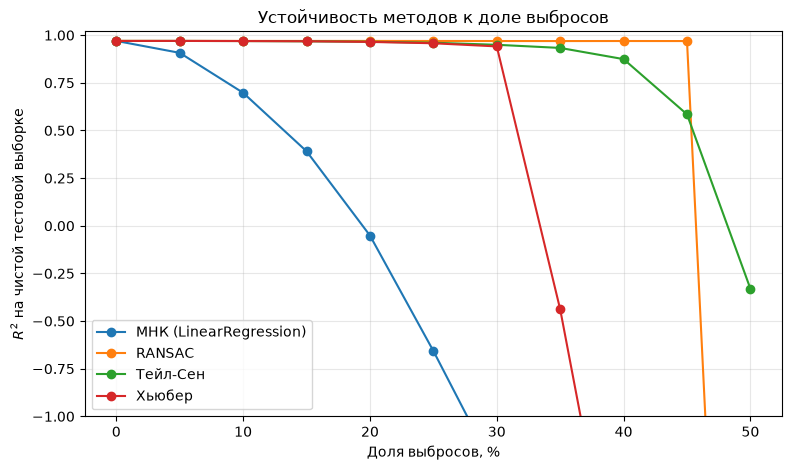

,МНК (LinearRegression),RANSAC,Тейл-Сен,Хьюбер
0,0.970,0.970,0.970,0.970
5,0.907,0.970,0.970,0.970
10,0.698,0.970,0.969,0.969
15,0.391,0.970,0.968,0.968
20,-0.051,0.970,0.966,0.965
25,-0.657,0.970,0.960,0.958
30,-1.300,0.969,0.950,0.941
35,-2.235,0.969,0.933,-0.438
40,-3.174,0.969,0.874,-2.185
45,-4.241,0.969,0.585,-3.770


In [24]:
fracs = np.arange(0, 0.51, 0.05)
curve = {name: [] for name in models2}
for frac in fracs:
    vals = {name: [] for name in models2}
    for seed in range(20):
        r = np.random.default_rng(1000 + seed)
        x = r.uniform(0, 10, n2); y = a_true + b_true * x + r.normal(0, 1, n2)
        k = int(round(frac * n2))
        idx = r.choice(n2, size=k, replace=False); y[idx] += r.uniform(20, 40, k)
        for name, proto in models2.items():
            m = type(proto)(**proto.get_params()).fit(x[:, None], y)
            vals[name].append(r2_score(y2_te, m.predict(x2_te[:, None])))
    for name in models2:
        curve[name].append(np.median(vals[name]))

fig, ax = plt.subplots(figsize=(9, 5))
for name, v in curve.items():
    ax.plot(fracs * 100, v, "o-", label=name)
ax.set_xlabel("Доля выбросов, %"); ax.set_ylabel("$R^2$ на чистой тестовой выборке")
ax.set_ylim(-1, 1.02); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Устойчивость методов к доле выбросов")
fig.savefig("figures/breakdown.png", dpi=150, bbox_inches="tight"); plt.show()
RESULTS["breakdown"] = {"fracs": fracs.round(2).tolist(), **{k: np.round(v, 3).tolist() for k, v in curve.items()}}
with open("figures/results.json", "w") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2, default=float)
pd.DataFrame(curve, index=(fracs * 100).round().astype(int)).round(3)

МНК портится сразу: уже при 5% выбросов $R^2$ падает, а при 20% становится отрицательным. Хьюбер держится до ~30%, а потом резко ломается: линейная часть его функции потерь всё равно учитывает большие остатки, и когда выбросов много, их суммарное «притяжение» побеждает. Тейл-Сен начинает заметно деградировать после 35–40% (теоретическая точка срыва медианы наклонов ≈29% относится к худшему случаю, а у нас выбросы случайные и частично «гасят» друг друга). RANSAC держится дольше всех — до 45%, пока «нормальных» точек большинство и случайные подвыборки находят консенсус; при 50% ломаются все методы.